# Association Rules — Product Recommendation System
**Owners:** Team B: Marwan, Moaaz

In [36]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

DATA = Path("../data")
RANDOM_STATE = 42
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules


## C. Train/Test Split
**Owner:** Moaaz


Mine rules on 80% of invoices, hold out 20%.

In [37]:

from sklearn.model_selection import train_test_split
basket = pd.read_csv(DATA / "online_retail_checkpoint_for_moaz.csv" ,index_col="InvoiceNo").astype(bool)
print("Basket Shape:", basket.shape)
basket_train , basket_test= train_test_split(basket, test_size=0.2 , random_state=RANDOM_STATE)
print("Train Invoices:", len(basket_train),"Test Invoices:", len(basket_test) )


Basket Shape: (449, 1694)
Train Invoices: 359 Test Invoices: 90


## Frequent Itemsets and Rules
**Owner:** Moaaz

`apriori` / `fpgrowth`, `association_rules`, tune `min_support`.

In [38]:
freq=apriori(basket_train, min_support=0.03, use_colnames=True)
print("Frequent Itemsets:",len(freq))
rules=association_rules(freq , metric="lift", min_threshold=1)
print("Rules:",len(rules))
rules.sort_values("lift", ascending=False).head(10)[["antecedents", "consequents", "support", "confidence", "lift"]]

Frequent Itemsets: 253
Rules: 246


,antecedents,consequents,support,confidence,lift
150,frozenset({SET OF 12 FAIRY CAKE BAKING CASES}),frozenset({SET OF 12 MINI LOAF BAKING CASES}),0.033426,0.750000,17.950000
151,frozenset({SET OF 12 MINI LOAF BAKING CASES}),frozenset({SET OF 12 FAIRY CAKE BAKING CASES}),0.033426,0.800000,17.950000
156,frozenset({SPACEBOY CHILDRENS CUP}),frozenset({SPACEBOY CHILDRENS BOWL}),0.041783,0.833333,17.598039
157,frozenset({SPACEBOY CHILDRENS BOWL}),frozenset({SPACEBOY CHILDRENS CUP}),0.041783,0.882353,17.598039
20,frozenset({CHILDRENS CUTLERY SPACEBOY}),frozenset({CHILDRENS CUTLERY DOLLY GIRL}),0.041783,0.833333,14.958333
21,frozenset({CHILDRENS CUTLERY DOLLY GIRL}),frozenset({CHILDRENS CUTLERY SPACEBOY}),0.041783,0.750000,14.958333
160,frozenset({WHITE SPOT BLUE CERAMIC DRAWER KNOB}),frozenset({WHITE SPOT RED CERAMIC DRAWER KNOB}),0.030641,0.785714,14.845865
161,frozenset({WHITE SPOT RED CERAMIC DRAWER KNOB}),frozenset({WHITE SPOT BLUE CERAMIC DRAWER KNOB}),0.030641,0.578947,14.845865
23,frozenset({COFFEE MUG PEARS DESIGN}),frozenset({COFFEE MUG APPLES DESIGN}),0.036212,0.928571,14.493789
22,frozenset({COFFEE MUG APPLES DESIGN}),frozenset({COFFEE MUG PEARS DESIGN}),0.036212,0.565217,14.493789


## D. Predict New Values
**Owner:** Moaaz

`recommend(basket)`.

In [39]:
def recommend(items, rules, top_n=5):
    basket = set(items)

    
    matching = rules[rules["antecedents"].apply(lambda lhs: lhs.issubset(basket))]

    matching = matching.sort_values(["confidence", "lift"], ascending=False)

    result = []
    for consequent in matching["consequents"]:
        for product in consequent:
            if product not in basket and product not in result:
                result.append(product)

    return result[:top_n]

print(recommend(["SET OF 12 FAIRY CAKE BAKING CASES"], rules))
print(recommend(["SPACEBOY CHILDRENS CUP"], rules))
print(recommend(["NOT A REAL PRODUCT"], rules))


['SET OF 12 MINI LOAF BAKING CASES']
['SPACEBOY CHILDRENS BOWL']
[]


## E. Predicted vs Actual
**Owner:** Moaaz

Recommended vs actually purchased on held-out invoices (hit rate).

Skipped (1 item): 4 | Tested: 86
Hits: 5 | Misses: 60 | No recommendation: 21
Hit rate: 5.8%
Hit rate when a recommendation was made: 7.7%


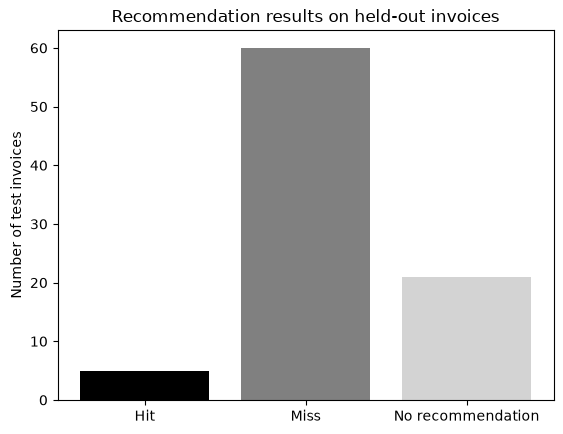

In [40]:
import random
rng=random.Random(RANDOM_STATE)
hits , misses , no_rec , skipped = 0,0,0,0

for invoice, row in basket_test.iterrows():
    items = list(row[row].index)
    if len(items)<2:
        skipped+=1
        continue
    hidden= rng.choice(items)
    visible=[i for i in items if i !=hidden]
    suggestions=recommend(visible , rules)
    if not suggestions:
     no_rec +=1
    elif hidden in suggestions:
        hits +=1
    else:
        misses +=1
        
    tested = hits + misses + no_rec
print("Skipped (1 item):", skipped, "| Tested:", tested)
print("Hits:", hits, "| Misses:", misses, "| No recommendation:", no_rec)
print(f"Hit rate: {hits / tested:.1%}")
print(f"Hit rate when a recommendation was made: {hits / (hits + misses):.1%}")
#The comparison Between the PRedictand Actual
plt.bar(["Hit", "Miss", "No recommendation"], [hits, misses, no_rec], color=["black", "grey", "lightgrey"])
plt.title("Recommendation results on held-out invoices")
plt.ylabel("Number of test invoices")
plt.show()



## F. Evaluation Metrics
**Owner:** Moaaz

Support, Confidence, Lift. Top rules table.

In [41]:
rules.sort_values("lift", ascending=False).head(10)[["antecedents", "consequents", "support", "confidence", "lift"]]

,antecedents,consequents,support,confidence,lift
150,frozenset({SET OF 12 FAIRY CAKE BAKING CASES}),frozenset({SET OF 12 MINI LOAF BAKING CASES}),0.033426,0.750000,17.950000
151,frozenset({SET OF 12 MINI LOAF BAKING CASES}),frozenset({SET OF 12 FAIRY CAKE BAKING CASES}),0.033426,0.800000,17.950000
156,frozenset({SPACEBOY CHILDRENS CUP}),frozenset({SPACEBOY CHILDRENS BOWL}),0.041783,0.833333,17.598039
157,frozenset({SPACEBOY CHILDRENS BOWL}),frozenset({SPACEBOY CHILDRENS CUP}),0.041783,0.882353,17.598039
20,frozenset({CHILDRENS CUTLERY SPACEBOY}),frozenset({CHILDRENS CUTLERY DOLLY GIRL}),0.041783,0.833333,14.958333
21,frozenset({CHILDRENS CUTLERY DOLLY GIRL}),frozenset({CHILDRENS CUTLERY SPACEBOY}),0.041783,0.750000,14.958333
160,frozenset({WHITE SPOT BLUE CERAMIC DRAWER KNOB}),frozenset({WHITE SPOT RED CERAMIC DRAWER KNOB}),0.030641,0.785714,14.845865
161,frozenset({WHITE SPOT RED CERAMIC DRAWER KNOB}),frozenset({WHITE SPOT BLUE CERAMIC DRAWER KNOB}),0.030641,0.578947,14.845865
23,frozenset({COFFEE MUG PEARS DESIGN}),frozenset({COFFEE MUG APPLES DESIGN}),0.036212,0.928571,14.493789
22,frozenset({COFFEE MUG APPLES DESIGN}),frozenset({COFFEE MUG PEARS DESIGN}),0.036212,0.565217,14.493789


## G. Supporting Visualizations
**Owner:** Marwan, Moaaz

Top items bar chart, support vs confidence scatter shaded by lift.

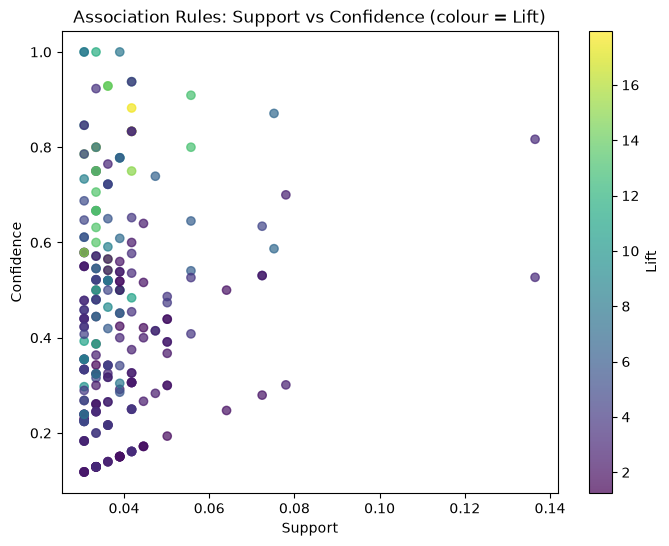

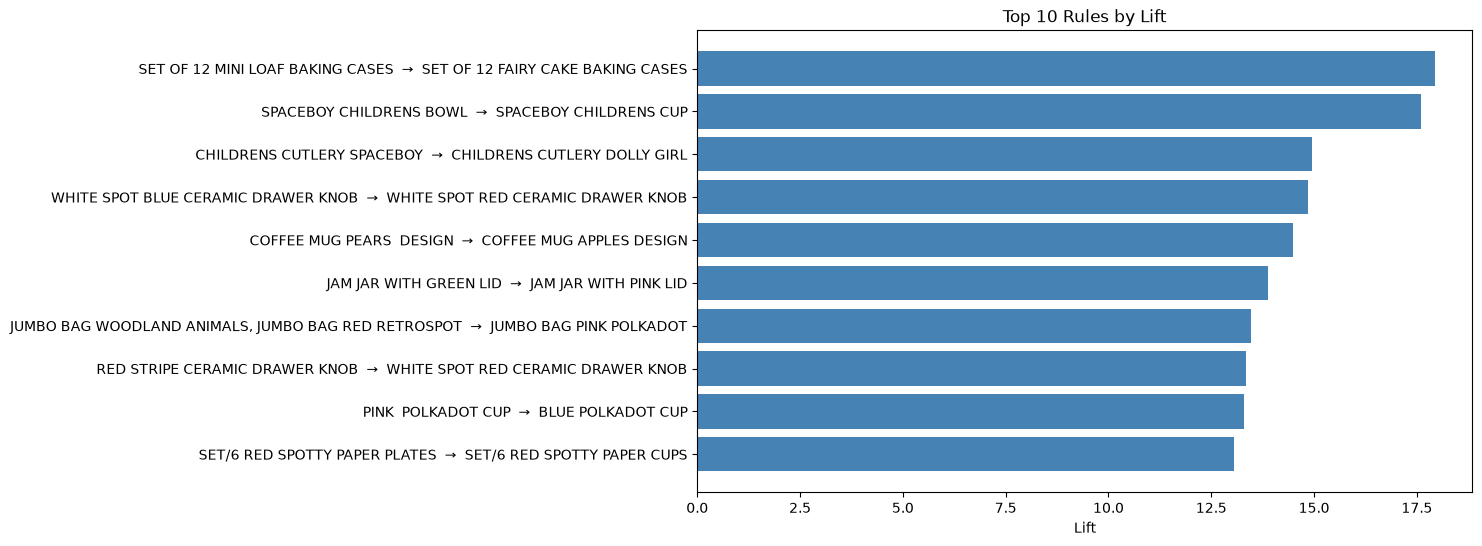

In [42]:
plt.figure(figsize=(8, 6))
points = plt.scatter(rules["support"], rules["confidence"], c=rules["lift"], cmap="viridis", alpha=0.7)
plt.colorbar(points, label="Lift")
plt.xlabel("Support")
plt.ylabel("Confidence")
plt.title("Association Rules: Support vs Confidence (colour = Lift)")
plt.show()

ranked = rules.sort_values(["lift", "confidence"], ascending=False)
pair = ranked.apply(lambda r: r["antecedents"] | r["consequents"], axis=1)
top = ranked[~pair.duplicated()].head(10)
labels = top["antecedents"].apply(lambda s: ", ".join(s)) + "  →  " + top["consequents"].apply(lambda s: ", ".join(s))
plt.figure(figsize=(10, 6))
plt.barh(labels, top["lift"], color="steelblue")
plt.gca().invert_yaxis()
plt.xlabel("Lift")
plt.title("Top 10 Rules by Lift")
plt.show()